# 🚢 타이타닉(Titanic) 데이터셋 기본 탐색적 데이터 분석 (EDA)

> **과목**: 데이터리터러시의 이해 (Week 03 ~ 04 연계 실습)  
> **데이터셋**: Kaggle `heptapod/titanic` (`train_and_test2.csv`, 총 1,309행)  
> **목적**: 데이터 수집·정제부터 기술통계 대푯값 비교, 단변량/다변량 시각화, 상관관계 및 인과 요인 탐색까지 완결된 EDA 파이프라인 수행

---

### 📋 분석 목차
1. **환경 설정 및 라이브러리 임포트** (한글 폰트 및 시각화 스타일 설정)
2. **데이터 로드 및 기본 구조 탐색 (Overview)** (더미 열 제거 및 컬럼 직관화)
3. **기술통계 기초 및 대푯값 비교 (평균 vs 중앙값의 함정)** (왜도 분석과 극단치 영향)
4. **데이터 품질 진단 및 정제 (Data Quality Diagnosis)** (중복값, 결측치, IQR 이상치 진단)
5. **단변량 탐색 분석 (Univariate Analysis)** (생존율, 성별, 나이, 요금 단독 분포)
6. **이변량 및 다변량 탐색 분석 (Bivariate & Multivariate EDA)**
   - 성별(`Sex`) vs 생존율 ("여성과 어린이 우선" 규범)
   - 객실등급(`Pclass`) vs 생존율 (사회경제적 계층 효과)
   - 객실등급 × 성별 교차 생존율 (상호작용)
   - 나이(`Age`) × 요금(`Fare`) 산점도와 어린이 보호선
   - 가족 규모(`FamilySize`) 파생변수 생성 및 비선형 관계
7. **상관관계 분석 (Correlation Analysis)** (피어슨 상관계수 및 히트맵)
8. **데이터 리터러시 관점의 종합 결론 및 시사점** (상관관계 vs 인과관계)


## 1. 환경 설정 및 라이브러리 임포트
분석에 필요한 주요 패키지를 불러오고, 운영체제에 맞는 한글 폰트와 시각화 스타일을 설정합니다.


In [2]:
import os
import platform
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# 운영체제별 한글 폰트 자동 설정 (macOS: AppleGothic, Windows: Malgun Gothic, Linux: NanumGothic)
os_name = platform.system()
if os_name == "Darwin":
    font_family = "AppleGothic"
elif os_name == "Windows":
    font_family = "Malgun Gothic"
else:
    font_family = "NanumGothic"

plt.rc("font", family=font_family)
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 기호 깨짐 방지
sns.set_theme(style="whitegrid", font=font_family)

%matplotlib inline
print(f"✅ 환경 설정 완료 (OS: {os_name}, Font: {font_family})")


PythonError: Traceback (most recent call last):
  File "<string>", line 7, in <module>
    exec(payload["code"], namespace)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<string>", line 23
    %matplotlib inline
    ^
SyntaxError: invalid syntax


## 2. 데이터 로드 및 기본 구조 탐색 (Overview)

KaggleHub 캐시 또는 데이터셋 다운로드를 통해 `train_and_test2.csv`를 불러옵니다.  
이 데이터셋에는 `zero`, `zero.1` 등 총 19개의 무의미한 더미 열이 포함되어 있으므로, 원본 파일은 보존하되 분석용 데이터프레임에서 필터링합니다.  
또한 타깃 변수명인 `2urvived`를 직관적인 `Survived`로 변경하고, 가독성을 위한 레이블 컬럼을 생성합니다.


In [3]:
# 데이터 파일 로드 (캐시 우선 확인)
cache_path = os.path.expanduser(
    "~/.cache/kagglehub/datasets/heptapod/titanic/versions/1/train_and_test2.csv"
)
if not os.path.exists(cache_path):
    import kagglehub
    dataset_path = kagglehub.dataset_download("heptapod/titanic")
    cache_path = os.path.join(dataset_path, "train_and_test2.csv")

raw_df = pd.read_csv(cache_path)
print(f"원시 데이터셋 크기: {raw_df.shape[0]:,}행 × {raw_df.shape[1]:,}열")

# 19개 더미 열(zero.*) 제거
df = raw_df.loc[:, ~raw_df.columns.str.match(r"zero(\.\d+)?$")].copy()

# 타깃 컬럼명 표준화
df["Survived"] = df["2urvived"]

# 파생 변수 생성: 가족 규모(FamilySize) 및 단독 탑승(IsAlone)
df["FamilySize"] = df["sibsp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# 시각화용 범주 레이블 매핑
df["Sex_Label"] = df["Sex"].map({0: "남성 (Male)", 1: "여성 (Female)"})
df["Pclass_Label"] = df["Pclass"].map({1: "1등석 (First)", 2: "2등석 (Second)", 3: "3등석 (Third)"})
df["Survived_Label"] = df["Survived"].map({0: "사망 (Perished)", 1: "생존 (Survived)"})
df["Embarked_Label"] = df["Embarked"].map({0.0: "Cherbourg(C)", 1.0: "Queenstown(Q)", 2.0: "Southampton(S)"})

print(f"정제 후 분석 데이터셋 크기: {df.shape[0]:,}행 × {df.shape[1]:,}열")
df.head()


PythonError: Traceback (most recent call last):
  File "<string>", line 6, in <module>
    exec(payload["preamble"], namespace)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<string>", line 23
    %matplotlib inline
    ^
SyntaxError: invalid syntax


In [3]:
# 컬럼별 자료형(Dtype) 및 Non-Null 수 요약
core_cols = ["Passengerid", "Survived", "Pclass", "Sex", "Age", "Fare", "sibsp", "Parch", "Embarked", "FamilySize", "IsAlone"]
summary_info = pd.DataFrame({
    "자료형(Dtype)": df[core_cols].dtypes,
    "결측치 수": df[core_cols].isnull().sum(),
    "결측 비율(%)": (df[core_cols].isnull().sum() / len(df) * 100).round(2),
    "고유값 수(nunique)": df[core_cols].nunique()
})
summary_info


,자료형(Dtype),결측치 수,결측 비율(%),고유값 수(nunique)
Passengerid,int64,0,0.00,1309
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Sex,int64,0,0.00,2
Age,float64,0,0.00,98
Fare,float64,0,0.00,281
sibsp,int64,0,0.00,7
Parch,int64,0,0.00,8
Embarked,float64,2,0.15,3
FamilySize,int64,0,0.00,9


## 3. 기술통계 기초 및 대푯값 비교 (평균 vs 중앙값의 함정)

> **💡 데이터 리터러시 4주차 핵심 질문**:  
> *"두 회사의 평균 연봉이 4,900만원으로 똑같습니다. 한 곳은 20명 중 17명이 평균 이하이고, 다른 곳은 전원이 평균 근처입니다. 왜 이런 일이 생겼을까요?"*

기술통계에서 **평균(Mean)**은 극단적인 이상치(Outlier)의 영향을 매우 강하게 받습니다.  
데이터의 **왜도(Skewness)**가 클 때는 평균 대신 **중앙값(Median)**과 **사분위수 범위(IQR)**를 대푯값으로 채택해야 왜곡을 피할 수 있습니다.


In [4]:
numeric_cols = ["Age", "Fare", "sibsp", "Parch", "FamilySize"]
desc = df[numeric_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
desc["IQR"] = desc["75%"] - desc["25%"]
desc["Skewness(왜도)"] = df[numeric_cols].skew()
desc.round(2)


,count,mean,std,min,25%,50%,75%,max,IQR,Skewness(왜도)
Age,1309.0,29.50,12.91,0.17,22.0,28.00,35.00,80.00,13.00,0.54
Fare,1309.0,33.28,51.74,0.00,7.9,14.45,31.28,512.33,23.38,4.37
sibsp,1309.0,0.50,1.04,0.00,0.0,0.00,1.00,8.00,1.00,3.84
Parch,1309.0,0.39,0.87,0.00,0.0,0.00,0.00,9.00,0.00,3.67
FamilySize,1309.0,1.88,1.58,1.00,1.0,1.00,2.00,11.00,1.00,2.85


### 🔍 대푯값 비교 분석: 운임(Fare) vs 나이(Age)
- **운임(`Fare`)**:
  - 평균: **$33.28**, 중앙값(50%): **$14.45** (평균이 중앙값의 **2.3배**)
  - 왜도(Skewness): **+4.37** (매우 긴 우측 꼬리 분포)
  - 원인: 대다수 승객은 $10~$30 사이를 지불했으나, 소수 1등석 부유층이 $512.33에 달하는 초고가 티켓을 구매함에 따라 산술평균이 크게 끌어올려짐.
  - **결론**: 타이타닉 승객의 일반적인 운임을 설명할 때는 **평균이 아닌 중앙값($14.45)과 IQR($23.38)**을 보고해야 사실을 왜곡하지 않음.
- **나이(`Age`)**:
  - 평균: **29.5세**, 중앙값: **28.0세**, 왜도: **+0.54**
  - 평균과 중앙값이 거의 일치하여 정규분포에 가까운 안정적인 형태를 보임.


## 4. 데이터 품질 진단 및 정제 (Data Quality Diagnosis)

데이터 정제는 단순한 청소가 아니라 후속 분석과 모델의 신뢰도를 결정하는 작업입니다.
다음 3가지 품질 지표를 진단합니다:
1. **중복값(Duplicate)** 검증
2. **결측치(Missing Values)** 진단 및 보정
3. **사분위수(IQR) 기반 이상치(Outliers)** 탐색


In [5]:
# 1. 중복값 검증
full_dups = df.duplicated().sum()
id_dups = df.duplicated(subset=["Passengerid"]).sum()
print(f"▶ 전체 완전 일치 중복 행 수: {full_dups}건")
print(f"▶ 승객 고유 ID(Passengerid) 중복 수: {id_dups}건 (1,309명 전원 고유 식별자 유지)")


▶ 전체 완전 일치 중복 행 수: 0건
▶ 승객 고유 ID(Passengerid) 중복 수: 0건 (1,309명 전원 고유 식별자 유지)


In [6]:
# 2. 결측치 진단 및 처리
missing_series = df.isnull().sum()
missing_cols = missing_series[missing_series > 0]
print("▶ 결측치가 존재하는 컬럼:")
print(missing_cols)

# Embarked(탑승항구) 결측 2건 확인
na_indices = df[df["Embarked"].isnull()].index.tolist()
print(f"\n- Embarked 결측 행 인덱스: {na_indices}")
print(f"- Embarked 최빈값: {df['Embarked'].mode()[0]} (Southampton)")

# 최빈값으로 안전하게 대치 (원칙: 극소수 결측치에 대해 분포를 훼손하지 않는 대치법 적용)
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Embarked_Label"] = df["Embarked_Label"].fillna("Southampton(S)")
print("✅ Embarked 결측치 2건 최빈값 대치 완료 (잔여 결측치 수: 0)")


▶ 결측치가 존재하는 컬럼:
Embarked          2
Embarked_Label    2
dtype: int64

- Embarked 결측 행 인덱스: [61, 829]
- Embarked 최빈값: 2.0 (Southampton)
✅ Embarked 결측치 2건 최빈값 대치 완료 (잔여 결측치 수: 0)


In [7]:
# 3. IQR(사분위수 범위) 기반 이상치 탐지 함수
def diagnose_iqr_outliers(series: pd.Series, col_name: str) -> dict:
    clean_series = series.dropna()
    q1 = clean_series.quantile(0.25)
    median = clean_series.quantile(0.50)
    q3 = clean_series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = clean_series[(clean_series < lower_bound) | (clean_series > upper_bound)]
    
    return {
        "컬럼": col_name,
        "Q1(25%)": round(q1, 2),
        "중앙값(50%)": round(median, 2),
        "Q3(75%)": round(q3, 2),
        "IQR": round(iqr, 2),
        "정상 하한선": round(lower_bound, 2),
        "정상 상한선": round(upper_bound, 2),
        "이상치 수": len(outliers),
        "이상치 비율(%)": round(len(outliers) / len(clean_series) * 100, 2)
    }

iqr_records = [
    diagnose_iqr_outliers(df["Fare"], "Fare (운임)"),
    diagnose_iqr_outliers(df["Age"], "Age (나이)")
]
pd.DataFrame(iqr_records)


,컬럼,Q1(25%),중앙값(50%),Q3(75%),IQR,정상 하한선,정상 상한선,이상치 수,이상치 비율(%)
0,Fare (운임),7.9,14.45,31.28,23.38,-27.17,66.34,171,13.06
1,Age (나이),22.0,28.00,35.00,13.00,2.50,54.50,101,7.72


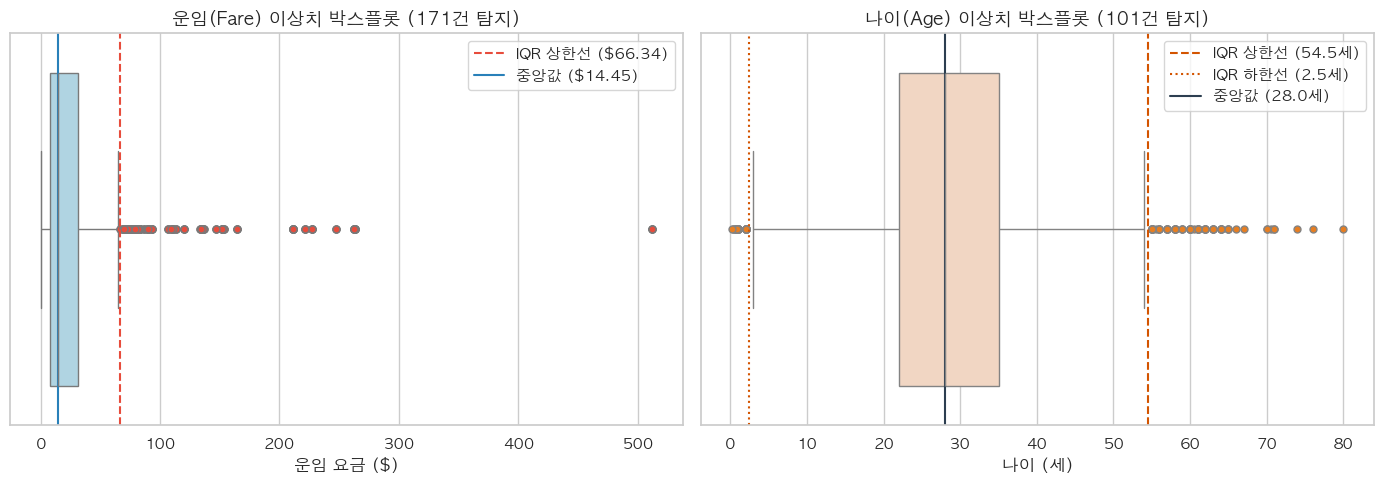

In [8]:
# 운임(Fare)과 나이(Age)의 이상치 박스플롯 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fare Boxplot
sns.boxplot(x=df["Fare"], ax=axes[0], color="#a8d8ea", flierprops={"markerfacecolor": "#e74c3c", "markersize": 5})
axes[0].axvline(66.34, color="#e74c3c", linestyle="--", linewidth=1.5, label="IQR 상한선 ($66.34)")
axes[0].axvline(14.45, color="#2980b9", linestyle="-", linewidth=1.5, label="중앙값 ($14.45)")
axes[0].set_title("운임(Fare) 이상치 박스플롯 (171건 탐지)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("운임 요금 ($)")
axes[0].legend()

# Age Boxplot
sns.boxplot(x=df["Age"], ax=axes[1], color="#f9d5bb", flierprops={"markerfacecolor": "#e67e22", "markersize": 5})
axes[1].axvline(54.5, color="#d35400", linestyle="--", linewidth=1.5, label="IQR 상한선 (54.5세)")
axes[1].axvline(2.5, color="#d35400", linestyle=":", linewidth=1.5, label="IQR 하한선 (2.5세)")
axes[1].axvline(28.0, color="#2c3e50", linestyle="-", linewidth=1.5, label="중앙값 (28.0세)")
axes[1].set_title("나이(Age) 이상치 박스플롯 (101건 탐지)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("나이 (세)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. 단변량 탐색 분석 (Univariate Analysis)

각 변수가 개별적으로 어떤 분포와 특성을 가지는지 확인합니다:
- **타깃 변수(`Survived`)**: 생존자와 사망자의 클래스 불균형(Imbalance) 정도
- **범주형 변수**: 성별(`Sex`), 객실등급(`Pclass`), 승선항구(`Embarked`)의 승객 수 분포
- **수치형 변수**: 나이(`Age`), 운임(`Fare`)의 분포 곡선 및 첨도/왜도


/var/folders/8g/sk6s6fh96vv8c7q77vg5cjvh0000gn/T/ipykernel_74438/2251523571.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Pclass_Label", palette="Blues_r", ax=axes[1], edgecolor="black", alpha=0.85)
/var/folders/8g/sk6s6fh96vv8c7q77vg5cjvh0000gn/T/ipykernel_74438/2251523571.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Embarked_Label", palette="Set2", ax=axes[2], edgecolor="black", alpha=0.85)


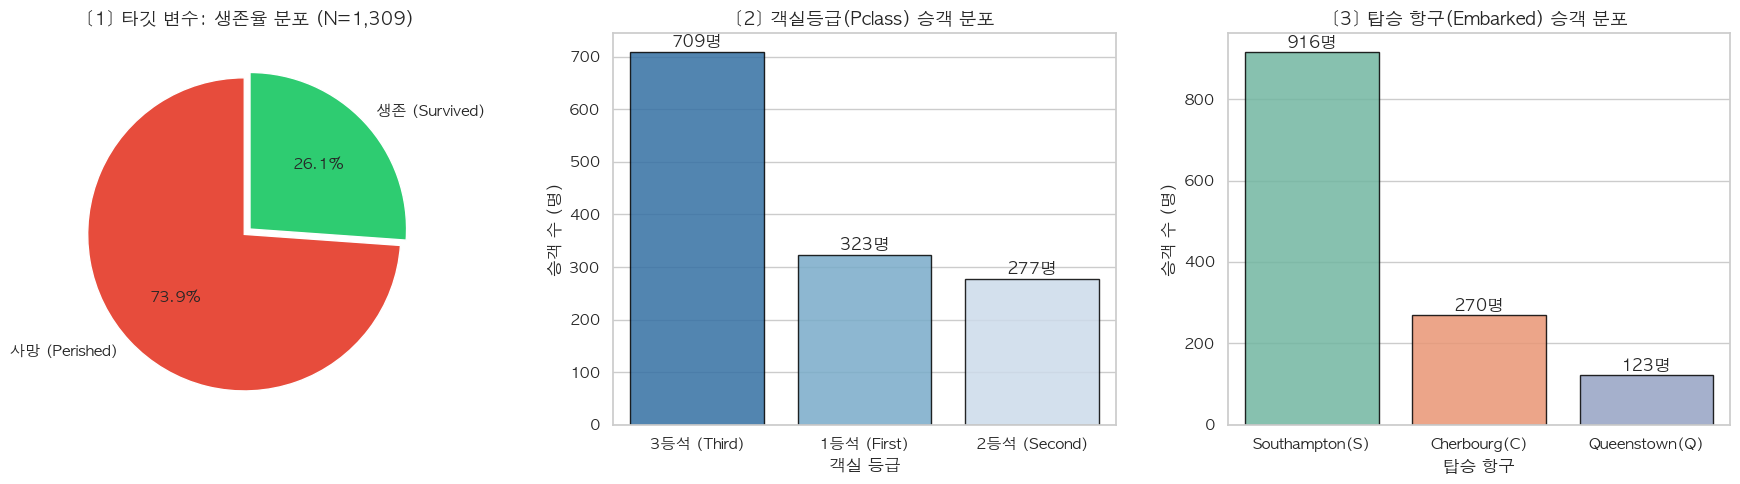

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 생존율 원형 차트
surv_counts = df["Survived_Label"].value_counts()
axes[0].pie(
    surv_counts,
    labels=surv_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#e74c3c", "#2ecc71"],
    explode=(0.05, 0),
    textprops={"fontsize": 11, "fontweight": "bold"}
)
axes[0].set_title("[1] 타깃 변수: 생존율 분포 (N=1,309)", fontsize=13, fontweight="bold")

# 2. 객실등급별 승객 수
sns.countplot(data=df, x="Pclass_Label", palette="Blues_r", ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("[2] 객실등급(Pclass) 승객 분포", fontsize=13, fontweight="bold")
axes[1].set_xlabel("객실 등급")
axes[1].set_ylabel("승객 수 (명)")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}명", (p.get_x() + p.get_width() / 2., p.get_height() + 10), ha="center", fontweight="bold")

# 3. 승선 항구별 승객 수
sns.countplot(data=df, x="Embarked_Label", palette="Set2", ax=axes[2], edgecolor="black", alpha=0.85)
axes[2].set_title("[3] 탑승 항구(Embarked) 승객 분포", fontsize=13, fontweight="bold")
axes[2].set_xlabel("탑승 항구")
axes[2].set_ylabel("승객 수 (명)")
for p in axes[2].patches:
    axes[2].annotate(f"{int(p.get_height())}명", (p.get_x() + p.get_width() / 2., p.get_height() + 10), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


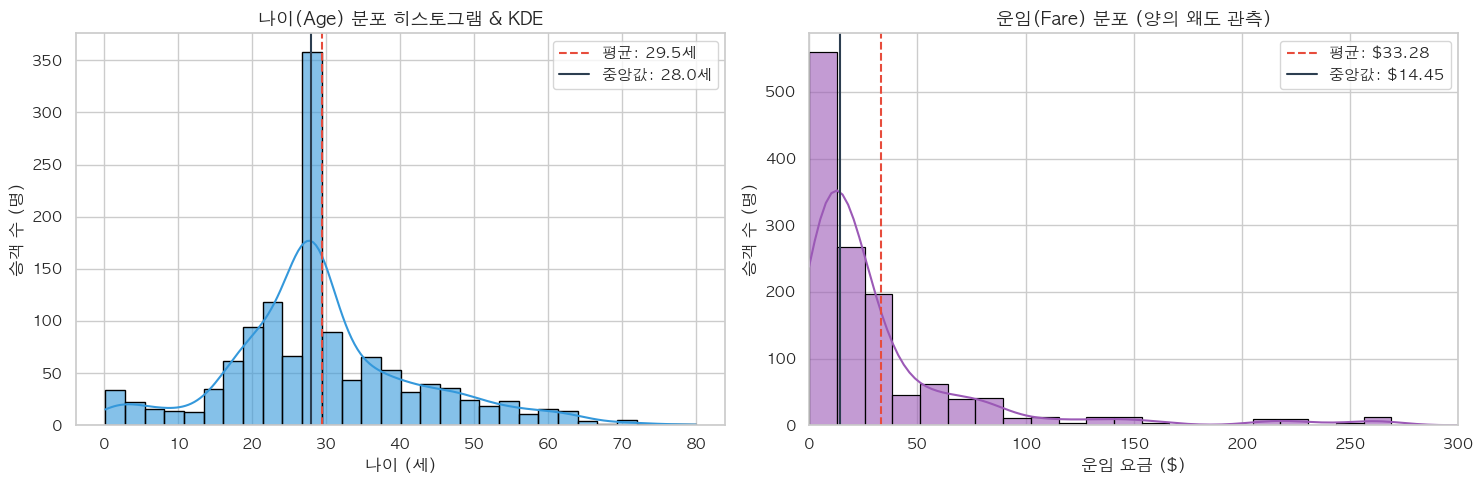

In [10]:
# 나이(Age)와 운임(Fare)의 분포 히스토그램 및 KDE 곡선
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age Histogram & KDE
sns.histplot(df["Age"], kde=True, ax=axes[0], color="#3498db", bins=30, edgecolor="black", alpha=0.6)
axes[0].axvline(df["Age"].mean(), color="#e74c3c", linestyle="--", label=f"평균: {df['Age'].mean():.1f}세")
axes[0].axvline(df["Age"].median(), color="#2c3e50", linestyle="-", label=f"중앙값: {df['Age'].median():.1f}세")
axes[0].set_title("나이(Age) 분포 히스토그램 & KDE", fontsize=13, fontweight="bold")
axes[0].set_xlabel("나이 (세)")
axes[0].set_ylabel("승객 수 (명)")
axes[0].legend()

# Fare Histogram & KDE (초고가 제외 영역 확대 표시)
sns.histplot(df["Fare"], kde=True, ax=axes[1], color="#9b59b6", bins=40, edgecolor="black", alpha=0.6)
axes[1].axvline(df["Fare"].mean(), color="#e74c3c", linestyle="--", label=f"평균: ${df['Fare'].mean():.2f}")
axes[1].axvline(df["Fare"].median(), color="#2c3e50", linestyle="-", label=f"중앙값: ${df['Fare'].median():.2f}")
axes[1].set_title("운임(Fare) 분포 (양의 왜도 관측)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("운임 요금 ($)")
axes[1].set_ylabel("승객 수 (명)")
axes[1].set_xlim(0, 300)  # 가독성을 위해 300 이하 영역 집중 표시
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. 이변량 및 다변량 탐색 분석 (Bivariate & Multivariate EDA)

생존 여부(`Survived`)와 각 특성 간의 상호작용 및 관계를 탐색합니다:
1. **성별(`Sex`) vs 생존율**: 여성 생존율과 남성 생존율 비교 및 통계적 유의성(카이제곱 검정)
2. **객실등급(`Pclass`) vs 생존율**: 사회경제적 계층 효과
3. **객실등급 × 성별 교차 분석**: 1등석 여성 vs 3등석 남성의 극단적 생존율 격차
4. **나이(`Age`) × 요금(`Fare`) 산점도**: 10세 이하 어린이 및 부유층 구명 효과
5. **가족 규모(`FamilySize`)의 비선형 보호 효과**: 단독 탑승 vs 적정 가족 vs 대가족


In [11]:
# 1. 성별 생존율 및 카이제곱 검정
sex_stats = df.groupby("Sex_Label")["Survived"].agg(["count", "sum", "mean"]).reset_index()
sex_stats.columns = ["성별", "탑승자수", "생존자수", "생존율"]
sex_stats["생존율(%)"] = (sex_stats["생존율"] * 100).round(1)

# 카이제곱 독립성 검정
contingency_table = pd.crosstab(df["Sex_Label"], df["Survived"])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency_table)

print(sex_stats[["성별", "탑승자수", "생존자수", "생존율(%)"]].to_string(index=False))
print(f"\n▶ 카이제곱 검정 결과: Chi2 = {chi2:.2f}, p-value = {p_val:.2e} (극도로 유의미)")


         성별  탑승자수  생존자수  생존율(%)
  남성 (Male)   843   109    12.9
여성 (Female)   466   233    50.0

▶ 카이제곱 검정 결과: Chi2 = 211.75, p-value = 5.69e-48 (극도로 유의미)


/var/folders/8g/sk6s6fh96vv8c7q77vg5cjvh0000gn/T/ipykernel_74438/1923529456.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sex_stats, x="성별", y="생존율(%)", palette=["#3498db", "#e74c3c"], ax=axes[1], edgecolor="black", alpha=0.85)


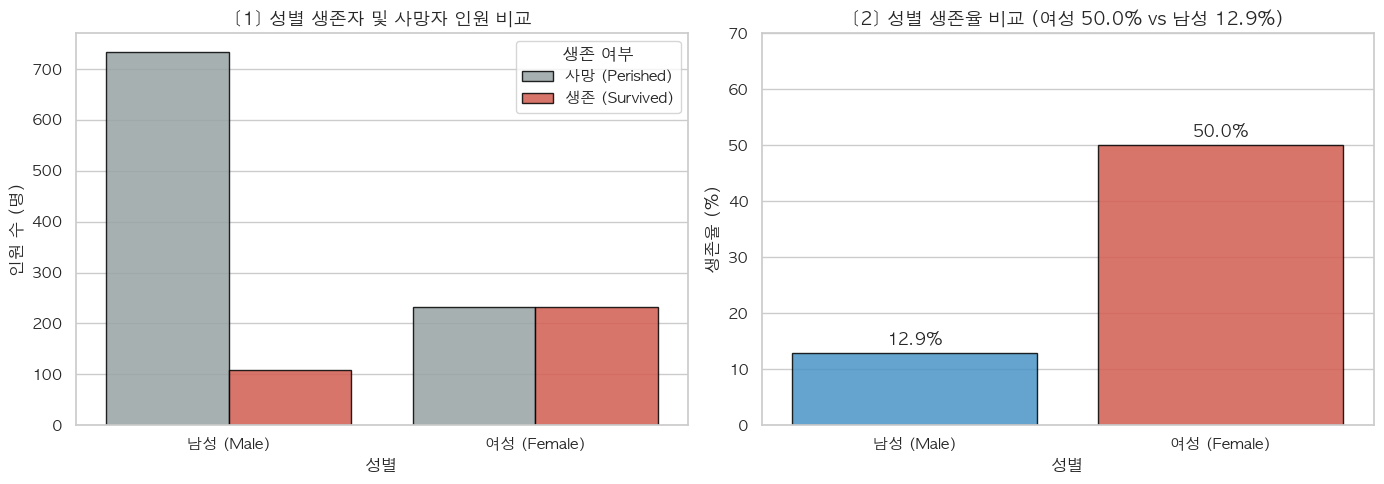

In [12]:
# 성별 생존율 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 성별 생존/사망자 수
sns.countplot(data=df, x="Sex_Label", hue="Survived_Label", palette={"사망 (Perished)": "#95a5a6", "생존 (Survived)": "#e74c3c"}, ax=axes[0], edgecolor="black", alpha=0.85)
axes[0].set_title("[1] 성별 생존자 및 사망자 인원 비교", fontsize=13, fontweight="bold")
axes[0].set_xlabel("성별")
axes[0].set_ylabel("인원 수 (명)")
axes[0].legend(title="생존 여부")

# 성별 생존율 막대
sns.barplot(data=sex_stats, x="성별", y="생존율(%)", palette=["#3498db", "#e74c3c"], ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("[2] 성별 생존율 비교 (여성 50.0% vs 남성 12.9%)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("생존율 (%)")
axes[1].set_ylim(0, 70)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1.5), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


/var/folders/8g/sk6s6fh96vv8c7q77vg5cjvh0000gn/T/ipykernel_74438/1861542720.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pclass_stats, x="Pclass_Label", y="Survived_Pct", palette="Blues_r", ax=axes[0], edgecolor="black", alpha=0.85)


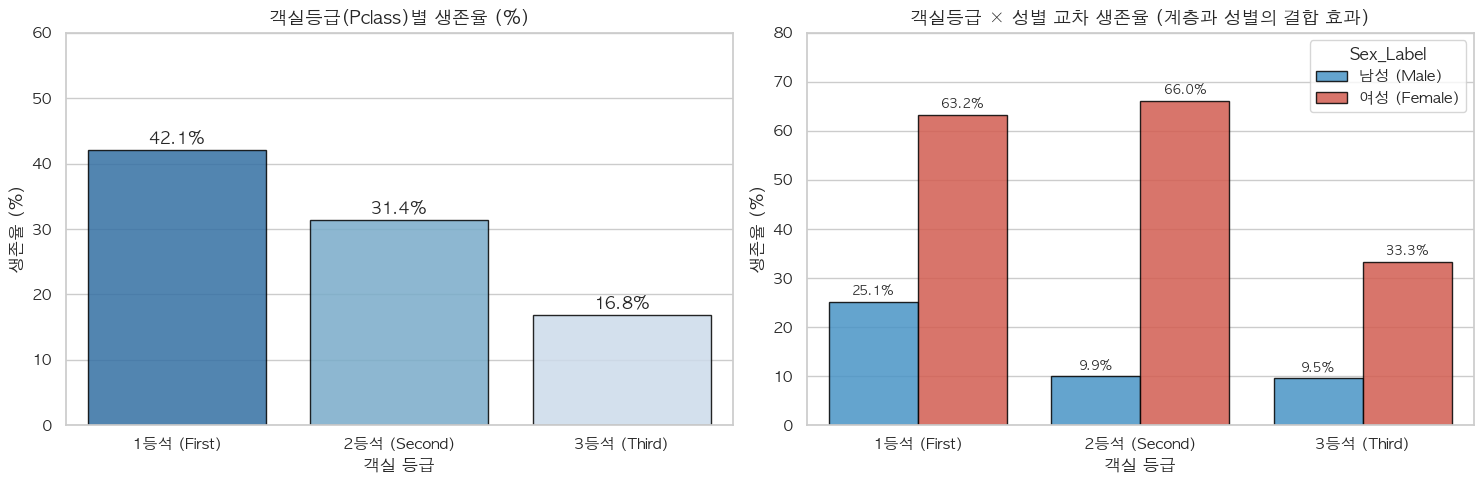

In [13]:
# 2. 객실등급(Pclass) 및 성별 × 객실등급 교차 생존율
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 객실등급별 생존율
pclass_stats = df.groupby("Pclass_Label")["Survived"].mean().reset_index()
pclass_stats["Survived_Pct"] = pclass_stats["Survived"] * 100
sns.barplot(data=pclass_stats, x="Pclass_Label", y="Survived_Pct", palette="Blues_r", ax=axes[0], edgecolor="black", alpha=0.85)
axes[0].set_title("객실등급(Pclass)별 생존율 (%)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("객실 등급")
axes[0].set_ylabel("생존율 (%)")
axes[0].set_ylim(0, 60)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha="center", fontweight="bold")

# 객실등급 × 성별 교차 생존율
cross_stats = df.groupby(["Pclass_Label", "Sex_Label"])["Survived"].mean().reset_index()
cross_stats["Survived_Pct"] = cross_stats["Survived"] * 100
sns.barplot(data=cross_stats, x="Pclass_Label", y="Survived_Pct", hue="Sex_Label", palette={"남성 (Male)": "#3498db", "여성 (Female)": "#e74c3c"}, ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("객실등급 × 성별 교차 생존율 (계층과 성별의 결합 효과)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("객실 등급")
axes[1].set_ylabel("생존율 (%)")
axes[1].set_ylim(0, 80)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.5), ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


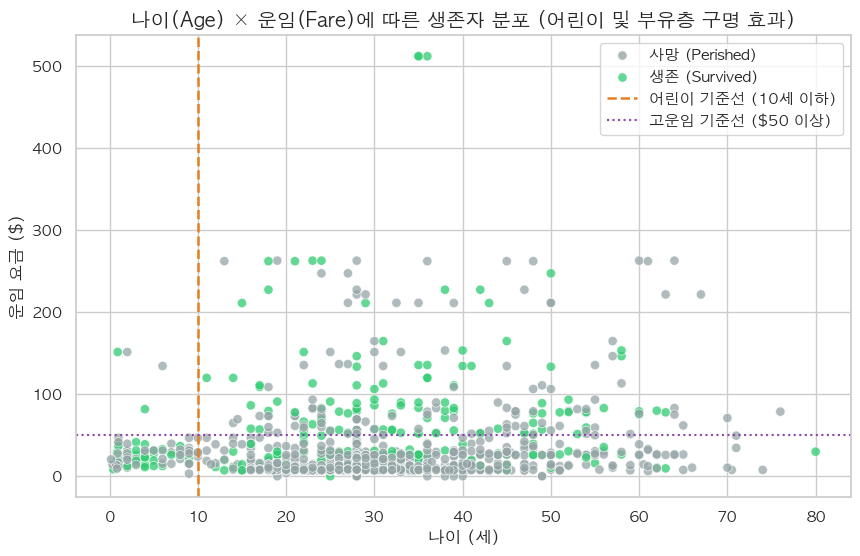

▶ 10세 이하 어린이 생존율: 44.2% vs 10세 초과 성인 생존율: 24.9%


In [14]:
# 3. 나이(Age) × 운임(Fare) 산점도 및 어린이 보호 효과
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived_Label",
    palette={"사망 (Perished)": "#95a5a6", "생존 (Survived)": "#2ecc71"},
    alpha=0.75,
    s=45
)
plt.axvline(10, color="#e67e22", linestyle="--", linewidth=1.8, label="어린이 기준선 (10세 이하)")
plt.axhline(50, color="#8e44ad", linestyle=":", linewidth=1.5, label="고운임 기준선 ($50 이상)")
plt.title("나이(Age) × 운임(Fare)에 따른 생존자 분포 (어린이 및 부유층 구명 효과)", fontsize=14, fontweight="bold")
plt.xlabel("나이 (세)")
plt.ylabel("운임 요금 ($)")
plt.legend(loc="upper right")
plt.show()

child_rate = df[df["Age"] <= 10]["Survived"].mean() * 100
adult_rate = df[df["Age"] > 10]["Survived"].mean() * 100
print(f"▶ 10세 이하 어린이 생존율: {child_rate:.1f}% vs 10세 초과 성인 생존율: {adult_rate:.1f}%")


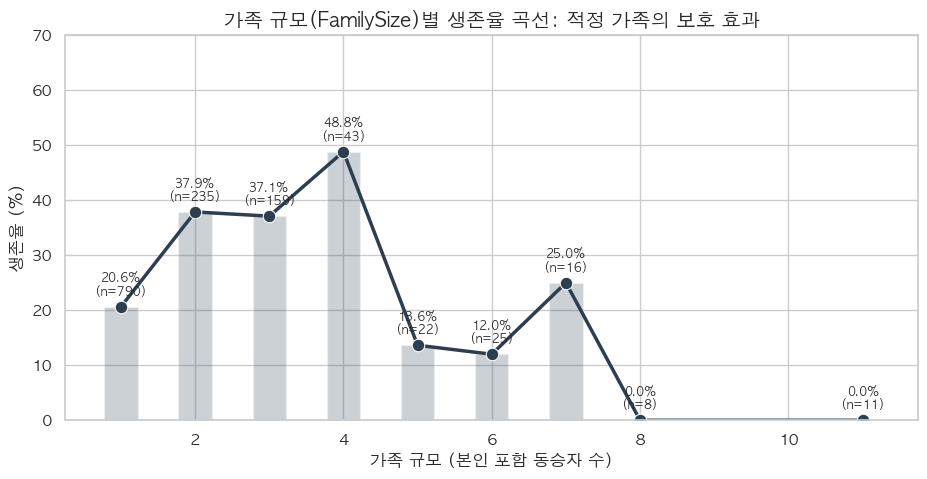

▶ 나홀로 탑승자 생존율: 20.6% vs 동승 가족 동반자 생존율: 34.5%


In [15]:
# 4. 가족 규모(FamilySize)와 생존율 (비선형 보호 효과)
fam_df = df.groupby("FamilySize")["Survived"].agg(["mean", "count"]).reset_index()
fam_df["Survived_Pct"] = fam_df["mean"] * 100

plt.figure(figsize=(11, 5))
sns.lineplot(data=fam_df, x="FamilySize", y="Survived_Pct", marker="o", markersize=9, color="#2c3e50", linewidth=2.5)
plt.bar(fam_df["FamilySize"], fam_df["Survived_Pct"], alpha=0.25, color="#34495e", width=0.45)
plt.title("가족 규모(FamilySize)별 생존율 곡선: 적정 가족의 보호 효과", fontsize=14, fontweight="bold")
plt.xlabel("가족 규모 (본인 포함 동승자 수)")
plt.ylabel("생존율 (%)")
plt.ylim(0, 70)

for _, row in fam_df.iterrows():
    plt.text(row["FamilySize"], row["Survived_Pct"] + 2, f"{row['Survived_Pct']:.1f}%\n(n={int(row['count'])})", ha="center", fontsize=8.5)

plt.show()

alone_rate = df[df["IsAlone"] == 1]["Survived"].mean() * 100
with_fam_rate = df[df["IsAlone"] == 0]["Survived"].mean() * 100
print(f"▶ 나홀로 탑승자 생존율: {alone_rate:.1f}% vs 동승 가족 동반자 생존율: {with_fam_rate:.1f}%")


## 7. 상관관계 분석 (Correlation Analysis)

주요 수치형 변수들 간의 피어슨 선형 상관계수(Pearson Correlation Coefficient)를 계산하고 히트맵을 생성합니다.  
대각선 기준 상삼각 영역을 마스킹하여 가독성을 높입니다.


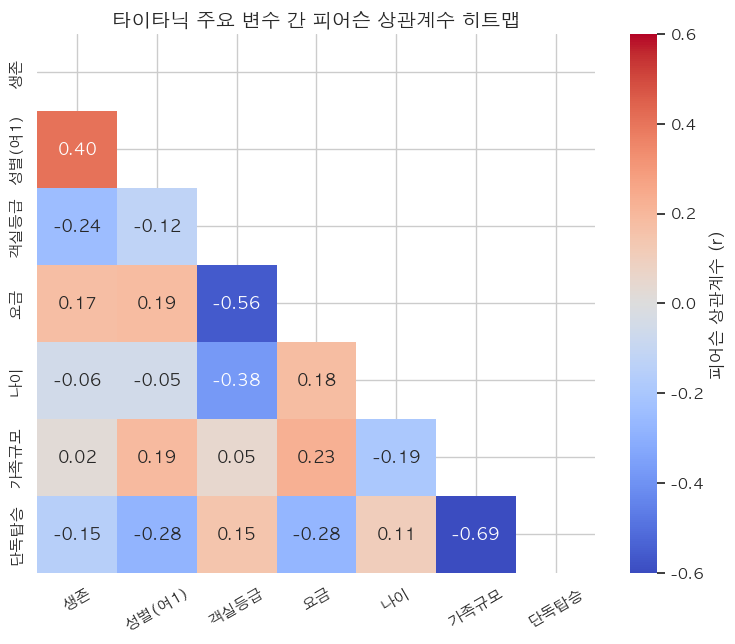

▶ 생존(Survived)과의 상관계수 순위:
Survived      1.0000
Sex           0.4040
Fare          0.1738
FamilySize    0.0206
Age          -0.0559
IsAlone      -0.1543
Pclass       -0.2447


In [16]:
corr_cols = ["Survived", "Sex", "Pclass", "Fare", "Age", "FamilySize", "IsAlone"]
corr_labels = ["생존", "성별(여1)", "객실등급", "요금", "나이", "가족규모", "단독탑승"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.6,
    vmax=0.6,
    xticklabels=corr_labels,
    yticklabels=corr_labels,
    cbar_kws={"label": "피어슨 상관계수 (r)"}
)
plt.title("타이타닉 주요 변수 간 피어슨 상관계수 히트맵", fontsize=14, fontweight="bold")
plt.xticks(rotation=30)
plt.show()

print("▶ 생존(Survived)과의 상관계수 순위:")
print(corr_matrix["Survived"].sort_values(ascending=False).round(4).to_string())


## 8. 데이터 리터러시 관점의 종합 결론 및 통찰 (Insights)

### 1. 상관관계 vs 인과관계의 비판적 구분
- **성별(`Sex`, $r = +0.404$)**:
  - 여성 생존율 50.0% vs 남성 12.9%.
  - 이는 우연한 상관관계가 아니라, 침몰 당시 선장과 선원들이 엄격히 집행한 **"여성과 어린이 우선(Women and children first)"**이라는 규범이 직접 작동한 **명확한 인과적 메커니즘(Causal Mechanism)**입니다.
- **운임(`Fare`, $r = +0.174$)과 객실등급(`Pclass`, $r = -0.245$)**:
  - 운임이 높아서 살아남은 것이 아닙니다. 고운임을 지불한 1등석 객실이 **선박 상부 갑판(Boat Deck)에 인접**해 있어 구명보트 탑승 지점에 신속히 도달할 수 있었던 **물리적·공간적 환경 요인이 교란 변수(Confounder)**로 작용한 것입니다.

### 2. 비선형 관계(Non-linear Relationship)의 발견
- 가족 규모(`FamilySize`)는 단순 선형 관계가 아닙니다.
- 나홀로 탑승자(생존율 20.6%)보다 **2~4인 적정 가족(생존율 37~49%)**의 생존율이 훨씬 높았지만, **5인 이상 대가족(생존율 0~25%)**은 위급 상황에서 가족 구성원을 모으느라 탈출 골든타임을 놓쳐 생존율이 급감하는 **역 U자형 비선형 보호 효과**를 보였습니다.

### 3. 기술통계가 주는 교훈 (대푯값 선택)
- 운임(`Fare`)은 왜도(+4.37)가 극심하여 소수 부유층의 이상치($512.33)로 인해 평균($33.28)이 중앙값($14.45)을 2배 이상 왜곡하고 있었습니다.
- 데이터 리터러시에서는 **데이터의 분포 형태(왜도, 이상치)를 먼저 진단하고, 그에 맞는 객관적 대푯값(중앙값, IQR)을 선택하는 비판적 사고**가 필수적입니다.

### 4. 후속 머신러닝 모델링(`predict_model.py`)과의 연결
- 본 EDA에서 규명된 핵심 특성들(`Sex`, `Pclass`, `Age`, `Fare`, `FamilySize`, `IsAlone`)은 머신러닝 예측 모델의 핵심 입력 특성으로 활용됩니다.
- 로지스틱 회귀를 통한 오즈비(Odds Ratio) 분석 결과, 여성은 남성에 비해 생존 승산이 **2.46배** 높고, 3등석은 1등석에 비해 생존 승산이 **50% 감소**하는 등 본 EDA의 발견과 일치하는 결과를 산출합니다.
